In [2]:
%pip -q install "transformers>=4.45,<5" "datasets>=3,<5" accelerate scipy pandas matplotlib

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [3]:
import os, re, json, random, platform
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForCausalLM
from scipy.stats import bootstrap
import matplotlib.pyplot as plt

SEED = 4057
N_TARGET = 200
N_BOOT = 2000
N_PERM = 10000
MODEL_ID = "Qwen/Qwen2.5-3B-Instruct"
OUT = Path('hw2_results'); OUT.mkdir(exist_ok=True)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
assert torch.cuda.is_available(), 'Enable a T4 GPU in Colab Runtime settings.'
GPU = torch.device('cuda:0')
BATCH_SIZE = 4  # Safe starting point for Colab T4 (16 GB); raise to 8 if memory allows.
print('PyTorch:', torch.__version__, '| GPU:', torch.cuda.get_device_name(0))
print('GPU memory (GB):', round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 1))

PyTorch: 2.14.1+cu130 | GPU: Tesla T4
GPU memory (GB): 14.6


In [4]:
ds = load_dataset('allenai/ai2_arc', 'ARC-Challenge', split='test')
print('Original test rows:', len(ds))

def parse_item(ex):
    labels = [str(x).strip().upper() for x in ex['choices']['label']]
    texts = [str(x).strip() for x in ex['choices']['text']]
    if len(texts) != 4 or len(set(texts)) != 4 or any(not x for x in texts): return None, 'not_four_distinct'
    if len(set(labels)) != 4: return None, 'duplicate_labels'
    gold = str(ex['answerKey']).strip().upper()
    if gold not in labels: return None, 'unresolved_gold'
    # Reject choices whose meaning depends on option index or letter.
    bad = re.compile(r'\b(?:all|none|both|either|neither)\s+of\s+(?:the\s+)?(?:above|below|these|them)\b|\b(?:option|choice|answer)\s*[A-D1-4]\b|\b(?:both|either|neither)\s+[A-D]\s+(?:and|or|nor)\s+[A-D]\b', re.I)
    if any(bad.search(t) for t in texts): return None, 'position_referential'
    gi = labels.index(gold)
    return {'id': str(ex['id']), 'question': str(ex['question']).strip(), 'options': texts, 'gold_idx': gi}, None

counts = {}
items = []
for ex in ds:
    item, reason = parse_item(ex)
    if reason: counts[reason] = counts.get(reason, 0) + 1
    else: items.append(item)
print('Filtering exclusions:', counts, 'Retained:', len(items))
assert len(items) > 0
rng = np.random.default_rng(SEED)
idx = rng.choice(len(items), size=min(N_TARGET,len(items)), replace=False)
items = [items[int(j)] for j in idx]
print('Sampled questions:', len(items))
print('Inspect sample:', json.dumps(items[0], indent=2, ensure_ascii=False))
(OUT/'filter_counts.json').write_text(json.dumps({'source':len(ds), 'excluded': counts, 'retained': len(ds)-sum(counts.values()), 'sampled':len(items)},indent=2))

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

ARC-Challenge/train-00000-of-00001.parqu(…):   0%|          | 0.00/190k [00:00<?, ?B/s]

ARC-Challenge/test-00000-of-00001.parque(…):   0%|          | 0.00/204k [00:00<?, ?B/s]

ARC-Challenge/validation-00000-of-00001.(…):   0%|          | 0.00/55.7k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/1119 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1172 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/299 [00:00<?, ? examples/s]

Original test rows: 1172
Filtering exclusions: {'not_four_distinct': 7} Retained: 1165
Sampled questions: 200
Inspect sample: {
  "id": "Mercury_7138460",
  "question": "Reef-building corals work together with photosynthetic algae that live in their tissues. Which type of energy is algae within a coral reef most likely able to use in order to survive?",
  "options": [
    "chemical",
    "mechanical",
    "radiant",
    "thermal"
  ],
  "gold_idx": 2
}


106

In [5]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
tokenizer.padding_side = 'left'
if tokenizer.pad_token is None: tokenizer.pad_token = tokenizer.eos_token
# Load the full model directly onto the GPU in FP16; do not silently offload to CPU.
model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID, torch_dtype=torch.float16, device_map={'': 0},
    low_cpu_mem_usage=True
)
assert next(model.parameters()).is_cuda, 'Model must reside on the GPU.'
print('Model loaded on:', next(model.parameters()).device)
model.eval()
letter_ids = [tokenizer.encode(ch, add_special_tokens=False) for ch in 'ABCD']
print('Candidate label tokenizations:', letter_ids)
assert all(len(ids)==1 for ids in letter_ids), 'Letter labels must be 1 token for next-token evaluation.'
label_ids = torch.tensor([ids[0] for ids in letter_ids], device=model.device)

def create_prompt(question, options):
    content = 'Choose the single best answer. Reply with ONLY one uppercase letter: A, B, C, or D.\n\n'
    content += 'Question: '+question+'\n'
    content += '\n'.join(f'{chr(65+j)}. {option}' for j,option in enumerate(options))
    content += '\nAnswer:'
    msgs = [{'role':'user','content':content}]
    return tokenizer.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)

records=[]
for item in items:
    original = item['options']
    for shift in range(4):
        order = [(k+shift)%4 for k in range(4)]
        gold_pos = order.index(item['gold_idx'])
        records.append({'id':item['id'], 'question':item['question'], 'shift':shift, 'gold_pos':gold_pos,
                        'gold_letter':'ABCD'[gold_pos], 'order':order,
                        'prompt':create_prompt(item['question'],[original[k] for k in order])})
assert len(records)==4*len(items)
assert all(set(r['gold_pos'] for r in records[4*i:4*i+4])==set(range(4)) for i in range(len(items)))

@torch.inference_mode()
def predict(prompts, batch_size=BATCH_SIZE):
    labels=[]; score_rows=[]
    for st in range(0,len(prompts),batch_size):
        enc = tokenizer(prompts[st:st+batch_size], padding=True, truncation=False, return_tensors='pt').to(model.device)
        logits = model(**enc).logits[:,-1,:]
        # These are unnormalized next-token scores, sufficient to rank the four candidates.
        candidate_scores=logits.index_select(1,label_ids).float().cpu().numpy()
        labels.extend([int(k) for k in candidate_scores.argmax(axis=1)])
        score_rows.extend(candidate_scores.tolist())
        if (st//batch_size)%20==0: print('Scored',min(st+batch_size,len(prompts)),'/',len(prompts))
    print('Peak GPU memory allocated (GB):', round(torch.cuda.max_memory_allocated(0)/1024**3, 2))
    return labels,score_rows

preds,scores = predict([r['prompt'] for r in records])
for r,p,s in zip(records,preds,scores):
    r['pred_pos']=p; r['pred_letter']='ABCD'[p]; r['correct']=int(p==r['gold_pos']); r['label_logits']=s
print('Predictions:',len(preds))

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

`torch_dtype` is deprecated! Use `dtype` instead!


... (3 outputs left out)

model-00002-of-00002.safetensors:   0%|          | 0.00/2.20G [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Model loaded on: cuda:0
Candidate label tokenizations: [[32], [33], [34], [35]]
Scored 4 / 800
Scored 84 / 800
Scored 164 / 800
Scored 244 / 800
Scored 324 / 800
Scored 404 / 800
Scored 484 / 800
Scored 564 / 800
Scored 644 / 800
Scored 724 / 800
Peak GPU memory allocated (GB): 6.17
Predictions: 800


In [6]:
df = pd.DataFrame(records)
df.drop(columns=['prompt']).to_csv(OUT/'all_predictions.csv',index=False)
# rows = original items; columns = gold position A,B,C,D
y = df.pivot(index='id',columns='gold_pos',values='correct').sort_index().to_numpy(dtype=np.float64)
assert y.shape == (len(items),4)
acc = y.mean(axis=0); mean_acc=float(acc.mean())
orig_acc=float(df.loc[df['shift']==0,'correct'].mean())
flip=((y.sum(axis=1)>0)&(y.sum(axis=1)<4)).astype(np.float64)
flip_rate=float(flip.mean())
score_counts=np.bincount(y.sum(axis=1).astype(int),minlength=5)
obs_max=float(np.max(acc)-np.min(acc))

rng=np.random.default_rng(SEED+1)
boot_idx=rng.integers(0,len(y),size=(N_BOOT,len(y)))
boot_y=y[boot_idx].mean(axis=1)
boot_flip=flip[boot_idx].mean(axis=1)
ci_acc=np.quantile(boot_y,[.025,.975],axis=0)
ci_flip=np.quantile(boot_flip,[.025,.975])

# Paired permutation max-statistic; preserves within-question correlation.
null_max=np.empty(N_PERM)
for b in range(N_PERM):
    shuf=np.argsort(rng.random(size=y.shape),axis=1)
    null_means=np.take_along_axis(y,shuf,axis=1).mean(axis=0)
    null_max[b]=null_means.max()-null_means.min()
pval=float((1+np.sum(null_max>=obs_max))/(N_PERM+1))

summary={'N':int(len(items)),'model':MODEL_ID,'seed':SEED,
'accuracy_by_gold_position':dict(zip('ABCD',map(float,acc))),
'accuracy_ci_95':{c:[float(ci_acc[0,i]),float(ci_acc[1,i])] for i,c in enumerate('ABCD')},
'position_averaged_accuracy':mean_acc,'original_order_accuracy':orig_acc,
'chance_baseline':.25,'max_position_accuracy_difference':obs_max,'position_permutation_pvalue':pval,
'flip_rate':flip_rate,'flip_ci_95':ci_flip.tolist(),'flip_threshold':.10,
'flip_hypothesis_supported':bool(ci_flip[0]>.10),
'permutation_score_distribution':{f'{i}/4':int(score_counts[i]) for i in range(5)}}
(OUT/'results.json').write_text(json.dumps(summary,indent=2))
print(json.dumps(summary,indent=2))

{
  "N": 200,
  "model": "Qwen/Qwen2.5-3B-Instruct",
  "seed": 4057,
  "accuracy_by_gold_position": {
    "A": 0.755,
    "B": 0.84,
    "C": 0.78,
    "D": 0.76
  },
  "accuracy_ci_95": {
    "A": [
      0.69,
      0.815
    ],
    "B": [
      0.785,
      0.89
    ],
    "C": [
      0.72,
      0.835
    ],
    "D": [
      0.695,
      0.815
    ]
  },
  "position_averaged_accuracy": 0.78375,
  "original_order_accuracy": 0.785,
  "chance_baseline": 0.25,
  "max_position_accuracy_difference": 0.08499999999999996,
  "position_permutation_pvalue": 0.0028997100289971,
  "flip_rate": 0.215,
  "flip_ci_95": [
    0.16,
    0.275
  ],
  "flip_threshold": 0.1,
  "flip_hypothesis_supported": true,
  "permutation_score_distribution": {
    "0/4": 23,
    "1/4": 14,
    "2/4": 10,
    "3/4": 19,
    "4/4": 134
  }
}


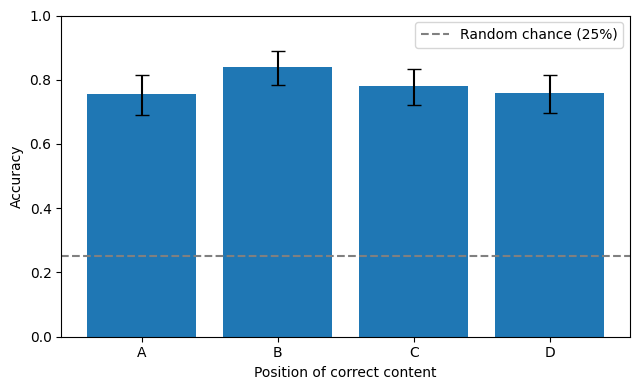

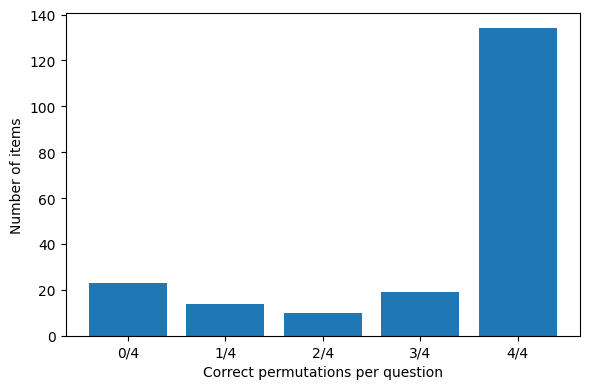

Paired position differences: {
  "A-B": {
    "estimate": -0.08499999999999996,
    "ci95": [
      -0.135,
      -0.03499999999999992
    ]
  },
  "A-C": {
    "estimate": -0.025000000000000022,
    "ci95": [
      -0.07000000000000006,
      0.020000000000000018
    ]
  },
  "A-D": {
    "estimate": -0.0050000000000000044,
    "ci95": [
      -0.05500000000000005,
      0.04999999999999993
    ]
  },
  "B-C": {
    "estimate": 0.05999999999999994,
    "ci95": [
      0.02487499999999992,
      0.09999999999999998
    ]
  },
  "B-D": {
    "estimate": 0.07999999999999996,
    "ci95": [
      0.030000000000000027,
      0.13
    ]
  },
  "C-D": {
    "estimate": 0.020000000000000018,
    "ci95": [
      -0.020000000000000018,
      0.06000000000000005
    ]
  }
}
Random unstable examples: [
  {
    "id": "Mercury_SC_413549",
    "question": "A student is going to walk outside to observe her shadow at four different times during a day. At which time will the student most likely notice h

203

In [7]:
fig,ax=plt.subplots(figsize=(6.5,4))
ax.bar(list('ABCD'),acc)
ax.errorbar(np.arange(4),acc,yerr=np.vstack([acc-ci_acc[0],ci_acc[1]-acc]),fmt='none',capsize=5,color='black')
ax.axhline(.25,linestyle='--',color='gray',label='Random chance (25%)')
ax.set_ylim(0,1); ax.set_xlabel('Position of correct content'); ax.set_ylabel('Accuracy'); ax.legend()
fig.tight_layout();fig.savefig(OUT/'position_accuracy.png',dpi=180);plt.show()
fig,ax=plt.subplots(figsize=(6,4))
ax.bar([f'{i}/4' for i in range(5)],score_counts)
ax.set_xlabel('Correct permutations per question');ax.set_ylabel('Number of items')
fig.tight_layout();fig.savefig(OUT/'item_consistency.png',dpi=180);plt.show()

pair_diffs={}
for p in range(4):
    for q in range(p+1,4):
        bd=boot_y[:,p]-boot_y[:,q]
        pair_diffs[f'{"ABCD"[p]}-{"ABCD"[q]}']={'estimate':float(acc[p]-acc[q]),'ci95':np.quantile(bd,[.025,.975]).tolist()}
(OUT/'paired_differences.json').write_text(json.dumps(pair_diffs,indent=2))
print('Paired position differences:',json.dumps(pair_diffs,indent=2))

grouped=df.groupby('id')['correct'].agg(['sum','count'])
unstable_ids=grouped.index[(grouped['sum']>0)&(grouped['sum']<grouped['count'])].tolist()
rng=np.random.default_rng(SEED+2)
chosen=rng.choice(unstable_ids,size=min(8,len(unstable_ids)),replace=False).tolist() if unstable_ids else []
examples=[]
for id_ in chosen:
    item=next(it for it in items if it['id']==id_)
    versions=df[df['id']==id_].sort_values('gold_pos')
    examples.append({'id':id_,'question':item['question'],'options_original':item['options'],
                     'gold_content':item['options'][item['gold_idx']],
                     'by_gold_position':[{'position':v.gold_letter,'predicted':v.pred_letter,'correct':bool(v.correct)} for v in versions.itertuples()]})
(OUT/'random_failure_examples.json').write_text(json.dumps(examples,indent=2,ensure_ascii=False))
print('Random unstable examples:',json.dumps(examples[:3],indent=2,ensure_ascii=False))

check_n=min(16,len(records))
rechecked,_=predict([r['prompt'] for r in records[:check_n]])
repeatability=float(np.mean(np.asarray(rechecked)==np.asarray(preds[:check_n])))
print('Deterministic repeatability:',repeatability)
assert repeatability == 1.0, 'Repeatability check failed; investigate nondeterminism.'
(OUT/'environment.json').write_text(json.dumps({'python':platform.python_version(),'torch':torch.__version__,
 'transformers':__import__('transformers').__version__,'datasets':__import__('datasets').__version__,
 'gpu':torch.cuda.get_device_name(0),'seed':SEED,'model':MODEL_ID,'repeatability':repeatability},indent=2))

In [8]:
import shutil
shutil.make_archive('hw2_results','zip',OUT)
print('Saved hw2_results.zip')
try:
    from google.colab import files
    files.download('hw2_results.zip')
except ImportError:
    pass

Saved hw2_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>